In [1]:
import pandas as pd
import numpy as np
import random
import pyomo.environ as pyo
from pyomo.environ import *
from pyomo.environ import SolverFactory
import yfinance as yf
from pathlib import Path
import os
import matplotlib.pyplot as plt


In [2]:
anos = ['2025-12-31',
 '2024-12-31',
 '2023-12-31',
 '2022-12-31',
 '2021-12-31',
 '2020-12-31',
 '2019-12-31',
 '2018-12-31',
 '2017-12-31',
 '2016-12-31',
  ]
anos.sort(reverse=False)
anos

['2016-12-31',
 '2017-12-31',
 '2018-12-31',
 '2019-12-31',
 '2020-12-31',
 '2021-12-31',
 '2022-12-31',
 '2023-12-31',
 '2024-12-31',
 '2025-12-31']

## LER OS RETORNOS, SCORE e SELIC

In [3]:
os.listdir('../../../novos-dados-retornos/plotagens/')

['app.ipynb',
 'df_acumulados_2015.csv',
 'df_acumulados_2016.csv',
 'df_acumulados_2017.csv',
 'df_acumulados_2018.csv',
 'df_acumulados_2019.csv',
 'df_acumulados_2020.csv',
 'df_acumulados_2021.csv',
 'df_acumulados_2022.csv',
 'df_acumulados_2023.csv',
 'df_acumulados_2024.csv',
 'df_acumulados_2025.csv',
 'df_acumulados_2026.csv']

In [4]:

# Retornos

dfs = {}
for ano in anos:
    ano_usado = ano.split('-')[0]
    nome = f'df_acumulados_{ano_usado}.csv'
    # caminho = Path('retornos_ativos_otimizacao') / nome
    dfs[ano_usado] = pd.read_csv('../../../novos-dados-retornos/plotagens/'+nome)
    dfs[ano_usado]['date'] = pd.to_datetime(dfs[ano_usado]['date'])
    dfs[ano_usado] = dfs[ano_usado].set_index('date')
    # dfs[ano_usado] = dfs[ano_usado].drop(columns=dfs[ano_usado].columns[(dfs[ano_usado] == 0).all()])
    
    # ativos_manter = (dfs[ano_usado]==0.0).mean()
    # c_manter = ativos_manter[ativos_manter<0.5].index
    # dfs[ano_usado] = dfs[ano_usado][c_manter]
    print(ano,'-',len(dfs[ano_usado].columns))
    

2016-12-31 - 100
2017-12-31 - 100
2018-12-31 - 100
2019-12-31 - 100
2020-12-31 - 100
2021-12-31 - 100
2022-12-31 - 100
2023-12-31 - 100
2024-12-31 - 100
2025-12-31 - 100


In [5]:
nomes_carteiras = os.listdir('../carteiras')
nomes_carteiras

['goal_programming',
 'linear_sharpe_mf',
 'linear_sharpe_piotroski',
 'min_var_mf',
 'min_var_piotroski']

In [6]:


retorno_ibov = []
acumulado_ibov = 1.0
ll=[]
for an in anos:
            
    ano = an.split('-')[0]
    # if ano == '2015' or ano=='2026':
        # continue
    # ---------- IBOV

    df_ibov = pd.read_csv(f'../dados_retornos/plotagem/dados/ibov/df_ibov_{ano}.csv', index_col='Date', parse_dates=True)
    df_ibov = df_ibov['IBOV']
    ibov_acumulado = (df_ibov+1).cumprod()
    ibov_acumulado = ibov_acumulado*acumulado_ibov
    acumulado_ibov = ibov_acumulado.iloc[-1]
    
    retorno_ibov.append(ibov_acumulado)


for nc in nomes_carteiras:
    retorno_series = []
    acumulado = 1.0
    for n in os.listdir('../carteiras/'+nc):
        df_portfolios = pd.read_csv(f'../carteiras/{nc}/{n}').drop(columns='Unnamed: 0')
        for an in anos:
            
            ano = an.split('-')[0]
            if ano == '2015' or ano=='2026':
                continue
            carteira = df_portfolios[df_portfolios['ano']==int(ano)]
            ativos = carteira['ativo'].tolist()
            pesos = carteira['peso'].tolist()
            #calculo do turnover, uma lista com peso de tudo, os que não estao na carteira vira zero, 
            #pegar info ano anterior
            carteira_t_1 = df_portfolios[df_portfolios['ano']==int(ano)-1]
            ativos_t_1 = carteira_t_1['ativo'].tolist()
            pesos_t_1 = carteira_t_1['peso'].tolist()
            pesos_t   = carteira.set_index('ativo')['peso']
            pesos_t_1 = carteira_t_1.set_index('ativo')['peso']
            turnover  = pesos_t.subtract(pesos_t_1, fill_value=0).abs().sum() / 2
            df = dfs[ano].copy()
            df = df[ativos]
            
            retorno_df = ((df*pesos).sum(axis=1)+1).cumprod()
            # retorno_df = ((1 + df).cumprod() * pesos).sum(axis=1)
            retorno_df = retorno_df*acumulado*(1-0.0003*turnover)
            acumulado = retorno_df.iloc[-1]
            retorno_series.append(retorno_df)
            

    ll.append(retorno_series)

    



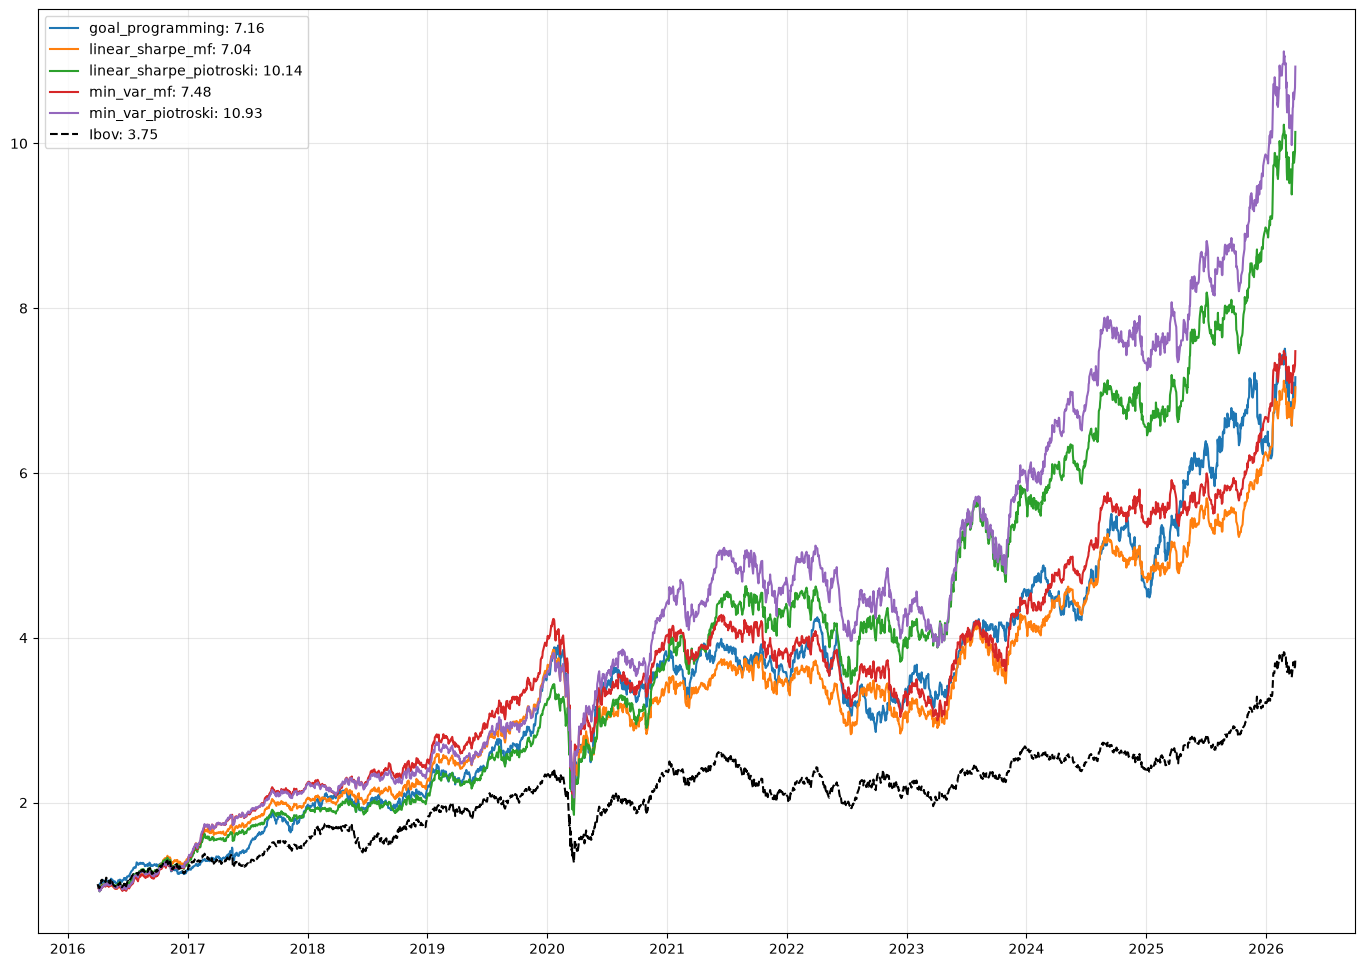

In [7]:
plt.figure(figsize=(17,12))
for v in range(len(ll)):    
    retorno_final = pd.concat(ll[v])
    retorno_ibov_final = pd.concat(retorno_ibov)

    plt.plot(retorno_final.index, retorno_final, label=f'{nomes_carteiras[v]}: {np.round(retorno_final.iloc[-1],2)}')
    
    # print(f'{'='*18}' \
    # f'{nomes_carteiras[v]}' \
    # '' \
    # f'{'='*18}')
    # print()

    # plt.axhline(11, color='gray', linewidth=0.8)
    
plt.plot(retorno_ibov_final.index, retorno_ibov_final, label=f"Ibov: {np.round(retorno_ibov_final.iloc[-1],2)}",color='black', linestyle='--')
plt.legend()
plt.grid(alpha=0.3)
# plt.yscale('log')
plt.show()




### Tentar pegar os marcadores de cada carteira

In [8]:
#selic
selic_d = pd.read_excel('../score-raspagem/selic/selic.xlsx')
# selic_d['Date'] = selic_d['Date'].
selic_d = selic_d.set_index('Date')
df_final = {}

lista_final = []

lista_composicao = []
for nc in nomes_carteiras:
    cart = os.listdir('../carteiras/'+nc)    
    print(cart)
    df_portfolios = pd.read_csv(f'../carteiras/{nc}/{cart[0]}').drop(columns='Unnamed: 0')
    for an in anos:
        
        ano = an.split('-')[0]
        if ano == '2015' or ano=='2026':
            continue
        carteira = df_portfolios[df_portfolios['ano']==int(ano)]
        ativos = carteira['ativo'].tolist()
        pesos = carteira['peso'].tolist()

        dc_composicao = {}


        texto = ' '.join(nc.split('_'))
        dc_composicao[texto+' '+ano] = {
            'ativos': ativos,
            'pesos':np.round(pesos,3),
            'quantidade_ativos': len(ativos),
        }
        lista_composicao.append(dc_composicao)
        df = dfs[ano].copy()
        df = df[ativos]
        retorno_df = (df*pesos).sum(axis=1)

        # SELIC
        slc = selic_d['selic'].reindex(retorno_df.index)/ 100
        excesso_retorno = retorno_df.sub(slc,axis=0)
        # print("SLC ",slc.isna().sum())
        # print("SLC ANO",(1+slc).prod()-1)

        # calculos
        retorno_medio = ((1+retorno_df).mean()-1)*100
        retorno_total_ano = ((1+retorno_df).prod()-1)*100
        porcentagem_valores_positivos = (retorno_df>0).mean()
        menor_retorno_valor = retorno_df.min()
        melhor_retorno_valor = retorno_df.max()

        # Espaço de verificações
        # Goal programminh queda de ~ -18% ... Qual dia?
        print(f"Data inicial: {retorno_df.index[0]} || Data Final: {retorno_df.index[-1]}")
        print(retorno_df.idxmin(), '-->',menor_retorno_valor)

        #riscos
        
        desvio_padrao_diario = retorno_df.std()
        # excesso_retorno = retorno_df- 0.001365
        sharpe_do_ano = (excesso_retorno.mean()/retorno_df.std())*np.sqrt(252)

        print(f"Carteira {texto} -> {ano}: \n"
              f"====== RETORNOS ============ \n"
              f"Retorno Médio Diário = {np.round(retorno_medio,2)}% \n"
              f"Retorno total do período = {np.round(retorno_total_ano,2)}% \n"
              f"% Dias Positivos {np.round(porcentagem_valores_positivos*100,2)}% \n"
              f"Pior Retorno: {np.round(menor_retorno_valor*100,2)}% & Melhor Retorno: {np.round(melhor_retorno_valor*100,2)}% \n"
              f"====== RISCO ============ \n"
              f"Sharpe: {sharpe_do_ano} \n"
              f"Desvio Padrão Diário: {np.round(desvio_padrao_diario*100,2)} %"
              )
        dados = []
        dados = [retorno_medio,retorno_total_ano,porcentagem_valores_positivos,menor_retorno_valor,melhor_retorno_valor,sharpe_do_ano,desvio_padrao_diario]
        dicio = {}
        dicio[texto+' '+ano]=dados
        f = pd.DataFrame(dicio)

        lista_final.append(f)
        

['carteiras_goal_programming.csv']
Data inicial: 2016-04-04 00:00:00 || Data Final: 2017-03-31 00:00:00
2016-12-01 00:00:00 --> -0.03548769895253577
Carteira goal programming -> 2016: 
====== RETORNOS ============ 
Retorno Médio Diário = 0.12% 
Retorno total do período = 33.52% 
% Dias Positivos 55.2% 
Pior Retorno: -3.55% & Melhor Retorno: 2.96% 
====== RISCO ============ 
Sharpe: 1.0796203404840354 
Desvio Padrão Diário: 1.03 %
Data inicial: 2017-04-04 00:00:00 || Data Final: 2018-03-29 00:00:00
2017-05-18 00:00:00 --> -0.07691668716816415
Carteira goal programming -> 2017: 
====== RETORNOS ============ 
Retorno Médio Diário = 0.19% 
Retorno total do período = 56.72% 
% Dias Positivos 59.52% 
Pior Retorno: -7.69% & Melhor Retorno: 3.32% 
====== RISCO ============ 
Sharpe: 1.960435810244472 
Desvio Padrão Diário: 1.28 %
Data inicial: 2018-04-03 00:00:00 || Data Final: 2019-03-29 00:00:00
2018-05-28 00:00:00 --> -0.04384022143100368
Carteira goal programming -> 2018: 
====== RETORNOS =

In [9]:
nomes_marcadores = [
    'retorno_medio','retorno_total_ano','porcentagem_valores_positivos','menor_retorno_valor','melhor_retorno_valor','sharpe_do_ano','desvio_padrao_diario'
]

In [10]:
d = pd.concat(lista_final,axis=1).set_index([nomes_marcadores])
# d.T.to_excel('indicadores.xlsx')
# d.T.to_csv('indicadores.csv')

In [11]:
dd={}
for i in range(10):
    cart = d.columns[i::10]
    # print(cart)
    dd[i] = d[cart]



In [12]:
dd[9].T

,retorno_medio,retorno_total_ano,porcentagem_valores_positivos,menor_retorno_valor,melhor_retorno_valor,sharpe_do_ano,desvio_padrao_diario
goal programming 2025,0.129519,34.276397,0.522088,-0.056054,0.052973,0.795080,0.014927
linear sharpe mf 2025,0.137676,38.944979,0.558233,-0.032795,0.036067,1.252536,0.010509
linear sharpe piotroski 2025,0.154266,44.647238,0.558233,-0.030163,0.039913,1.448816,0.010903
min var mf 2025,0.110969,30.355943,0.578313,-0.032195,0.030608,0.944788,0.009445
min var piotroski 2025,0.141140,40.079511,0.550201,-0.031798,0.044673,1.282266,0.010694


In [13]:
df_composicao_final = []
for comp in lista_composicao:
    df = pd.DataFrame(comp).T
    df_composicao_final.append(df)

In [14]:
dd_comp={}
for i in range(10):
    # print(cart)
    dd_comp[i] = df_composicao_final[i::10]


In [15]:
pd.set_option('display.max_colwidth', None)
# print(sum(pd.concat(dd_comp[8]).iloc[8]['pesos']))
pd.concat(dd_comp[1])

,ativos,pesos,quantidade_ativos
goal programming 2017,"[CVCB3, EGIE3, ISAE4, MGLU3, MOTV3, SBSP3, VALE3]","[0.15, 0.15, 0.15, 0.15, 0.1, 0.15, 0.15]",7
linear sharpe mf 2017,"[ANIM3, AZZA3, B3SA3, BBSE3, BEEF3, CSMG3, EMBJ3, ENEV3, FLRY3, KLBN11, SAUD3, SMTO3, TAEE11, TOTS3, VIVT3]","[0.076, 0.04, 0.028, 0.025, 0.123, 0.123, 0.049, 0.121, 0.042, 0.038, 0.078, 0.013, 0.043, 0.052, 0.15]",15
linear sharpe piotroski 2017,"[ALPA4, ANIM3, AZZA3, BEEF3, CSMG3, EMBJ3, ENEV3, ENGI11, FLRY3, KLBN11, MRVE3, NATU3, TAEE11, TOTS3, VIVT3]","[0.037, 0.078, 0.027, 0.142, 0.13, 0.063, 0.119, 0.02, 0.052, 0.051, 0.017, 0.025, 0.053, 0.036, 0.15]",15
min var mf 2017,"[ANIM3, AZZA3, BBSE3, BEEF3, CSMG3, ENEV3, FLRY3, KLBN11, PRIO3, SAUD3, SMTO3, TAEE11, TOTS3, UGPA3, VIVT3]","[0.072, 0.037, 0.03, 0.124, 0.082, 0.15, 0.044, 0.04, 0.047, 0.118, 0.029, 0.031, 0.059, 0.024, 0.112]",15
min var piotroski 2017,"[ALPA4, ANIM3, AZZA3, BEEF3, CSMG3, ENEV3, ENGI11, FLRY3, KLBN11, MRVE3, PRIO3, SMTO3, TAEE11, TOTS3, VIVT3]","[0.032, 0.088, 0.022, 0.148, 0.087, 0.15, 0.032, 0.052, 0.059, 0.023, 0.055, 0.019, 0.035, 0.051, 0.146]",15


In [16]:
lista_composicao_final_final = []
for i in range(len(dd_comp)):
    didi = pd.concat(dd_comp[i])
    lista_composicao_final_final.append(didi)

pd.concat(lista_composicao_final_final).to_excel("comp_comp.xlsx")

In [17]:
pd.concat(df_composicao_final).to_excel('compo.xlsx')

In [18]:
# ================= INDICADORES DO PERÍODO COMPLETO (todos os anos juntos) =================
def var_cvar(retornos, alfa):
    # retornos em ordem crescente (piores primeiro), como no artigo
    r = np.sort(retornos.values)
    M = len(r)
    k = int(np.floor(M*(1-alfa))) + 1
    var = -r[k-1]                          # perda positiva, como na tabela do artigo
    cvar = -r[:k].sum() / (M*(1-alfa))
    return var, cvar

def indicadores(r, rf):
    # r: retornos diários da carteira (Series) | rf: Selic diária (Series, mesmas datas)
    mean_return = r.mean()
    rf_medio = rf.mean()
    desvio = r.std()
    downside = np.sqrt((np.minimum(r, 0)**2).sum() / len(r))

    var95, cvar95 = var_cvar(r, 0.95)
    var97, cvar97 = var_cvar(r, 0.97)
    _, cvar95_neg = var_cvar(-r, 0.95)
    _, cvar97_neg = var_cvar(-r, 0.97)

    acumulado = (1 + r).cumprod()
    max_drawdown = (acumulado / acumulado.cummax() - 1).min()
    anos_periodo = len(r) / 252

    return {
        # ---- Artigo 3 (diários) ----
        'mean_return': mean_return,
        'sharpe': (mean_return - rf_medio) / desvio,
        'sortino': (mean_return - rf_medio) / downside,
        'downside_deviation': downside,
        'var_95': var95,
        'var_97': var97,
        'cvar_95': cvar95,
        'cvar_97': cvar97,
        'rachev_95': cvar95_neg / cvar95,
        'rachev_97': cvar97_neg / cvar97,
        'starr_95': (mean_return - rf_medio) / cvar95,
        'starr_97': (mean_return - rf_medio) / cvar97,
        # ---- complementares (anualizados) ----
        'valor_total': acumulado.iloc[-1], #acumulado.iloc[-1] - 1,
        'retorno_anualizado': acumulado.iloc[-1] ** (1 / anos_periodo) - 1,
        'volatilidade_anual': desvio * np.sqrt(252),
        'sharpe_anual': (mean_return - rf_medio) / desvio * np.sqrt(252),
        'max_drawdown': max_drawdown,
        'dias_positivos': (r > 0).mean(),
    }


tabela = {}

# ---------- CARTEIRAS ----------
for nc in nomes_carteiras:
    cart = os.listdir('../carteiras/'+nc)
    df_portfolios = pd.read_csv(f'../carteiras/{nc}/{cart[0]}').drop(columns='Unnamed: 0')

    retornos_todos_anos = []
    for an in anos:
        ano = an.split('-')[0]
        if ano == '2015' or ano=='2026':
            continue
        carteira = df_portfolios[df_portfolios['ano']==int(ano)]
        ativos = carteira['ativo'].tolist()
        pesos = carteira['peso'].tolist()

        df = dfs[ano].copy()
        df = df[ativos]
        retorno_df = (df*pesos).sum(axis=1)
        retornos_todos_anos.append(retorno_df)

    r = pd.concat(retornos_todos_anos)                       # série diária do período inteiro
    rf = selic_d['selic'].reindex(r.index) / 100
    tabela[' '.join(nc.split('_'))] = indicadores(r, rf)

# ---------- IBOV (benchmark) ----------
ibov_todos_anos = []
for an in anos:
    ano = an.split('-')[0]
    df_ibov = pd.read_csv(f'../dados_retornos/plotagem/dados/ibov/df_ibov_{ano}.csv', index_col='Date', parse_dates=True)
    ibov_todos_anos.append(df_ibov['IBOV'])

r_ibov = pd.concat(ibov_todos_anos)
rf_ibov = selic_d['selic'].reindex(r_ibov.index) / 100
tabela['Ibov'] = indicadores(r_ibov, rf_ibov)

tabela_final = pd.DataFrame(tabela)
print("Período:", r.index[0].date(), "a", r.index[-1].date(), "|", len(r), "dias")
ff = tabela_final.T[['mean_return','sharpe_anual','cvar_95','max_drawdown']].round(5)
ff.to_excel('ff.xlsx')

Período: 2016-04-04 a 2026-03-31 | 2482 dias
